# Predicting a new donor's stimulated quantiles: where we started, where we are

**Task.** For a donor never seen in training, predict every stimulated quantile (stim × celltype × 13 functional
markers × q50 / q75 / q90) from the donor's **Unstim** profile.

**One evaluation for everything.** Leave-one-donor-out:
- Each of the 19 donors is predicted once, by models trained on the other 18. All features, means and PCs are refitted
  within each fold.
- Every method is scored on the same cases: PI and IL33 left out (mostly plate noise), q50-q90, and the **selected
  features**.
- Selected features = the any-quantile rule of `heldout/inclusion.py`: mean over the 19 donors of
  |stim − Unstim| > 0.1 at that quantile. All cases with a visible effect are reported too ("floor" set).
- Each donor counts once. Confidence intervals and tests are over donors, so the donor is the unit.

**Methods**

| family | method | what it is |
|---|---|---|
| baseline | shift | training-mean stim effect added to the donor's own Unstim value |
| CellOT | CellOT (paper) | the paper's unpaired CellOT architecture and selection, 20k iterations (`lc/train.py`) |
| | CellOT (paired) | paired cells per donor, no donor information (`cond_train --ctx none`) |
| | CellOT + covariate | whole-blood covariate `pcblood` (own + 4 dominant celltypes' Unstim medians + frequencies → 3 PCs), its FiLM variant, and phenotype subclusters |
| | CellOT + shift | 0.5 / 0.5 average (the previous best: paired CellOT + shift) |
| tabular | TabPFN / LightGBM | predict what the shift misses from the donor's Unstim profile; prediction = shift + full correction |
| mixes | 0.4 CellOT + 0.6 model | any CellOT version with any tabular model |

Tabular feature sets:
- S0: the feature itself (u_dev, mu_u, eff, sd_u, noise_u, q, marker).
- S1_5 / S2 / S3 / S4_3: + 5 PCs of the own-celltype profile / + 3 frequency PCs / + HV/PV / + 3 whole-blood PCs.
- L1cat: S0 + the raw 65 own-celltype values (13 markers × 5 quantiles).
- L1F: L1cat + 28 log frequencies. L1all_pc / L1all_raw: L1cat + frequencies (PCs / raw) + HV/PV + 3 whole-blood PCs.
- L1X / L1M / L1allM: + the same quantile × marker in the other celltypes. L1M uses all 28 celltypes plus their
  donor-wide mean and sd; L1X uses the 4 dominant celltypes plus that mean and sd; L1allM = L1all_raw + L1M's extras.

**Metrics.**
- **MSE** (main) and **MAE**, arcsinh units.
- **Share of the shift's error removed** = 1 − MSE / MSE(shift).
- **Share of the reducible error removed** = (MSE(shift) − MSE) / (MSE(shift) − noise floor). This is how much of
  what is both patient-specific and real has been predicted.
- **between_R2**: whether predicted differences between donors follow the real ones (each feature centred across the
  19 donors). Its ceiling is set by the noise.
- **Noise floor**: donor × well noise of the response (stim − Unstim) over the donor's three DMSO plate-control wells,
  with the well effect shared by all donors removed (`lc/noise_floor_lodo.py`). No model can go below it.

In [1]:
import sys; sys.path.insert(0, "/scratch/users/bmerwan/atlas_heldout")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lc.paths import WORK
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
FIN = WORK / "tab" / "final"
M = pd.read_csv(FIN / "metrics_rule.csv").set_index("method"); Mf = pd.read_csv(FIN / "metrics_floor.csv").set_index("method")
BS = pd.read_csv(FIN / "by_stim_rule.csv", index_col=0); BD = pd.read_csv(FIN / "by_donor_rule.csv", index_col=0)
VR = pd.read_csv(FIN / "variance_rule.csv")
# dataviz reference palette: categorical slots in fixed order, neutral greys, diverging blue - grey - red
S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, REF = "#0b0b0b", "#52514e", "#e6e5e0", "#8a8a85"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})
has = lambda m: m in M.index
FLOOR = M.noise_floor_MSE.iloc[0]; CEIL = M.between_R2_ceiling.iloc[0]
best = M.drop(index=[m for m in M.index if m == "shift"]).MSE.idxmin()
OLD = "CellOT_paired+shift"
fam = lambda m: ("mix" if m.startswith("0.4 ") else "TabPFN" if m.startswith("pfn_") else "LightGBM" if m.startswith("lgb_")
                 else "baseline / CellOT")
COL = {"baseline / CellOT": REF, "TabPFN": S1, "LightGBM": S2, "mix": S3}
print(f"{int(M.n_cases.iloc[0])} selected cases, 19 donors; {len(M)} methods; noise floor MSE {FLOOR:.4f}; between_R2 ceiling {CEIL:.3f}")
print("missing (job not finished?):", [m for m in ["CellOT_pcblood", "CellOT_film", "CellOT_cluster", "pfn_S0", "pfn_S4_3"] if not has(m)])

34086 selected cases, 19 donors; 60 methods; noise floor MSE 0.0036; between_R2 ceiling 0.960
missing (job not finished?): []


## 1. The path: from the paper's CellOT to the best model

Milestones in the order they were tried. Dots are per-donor MSE on the selected features with a 95 % bootstrap CI over
donors; the dashed line is the noise floor.

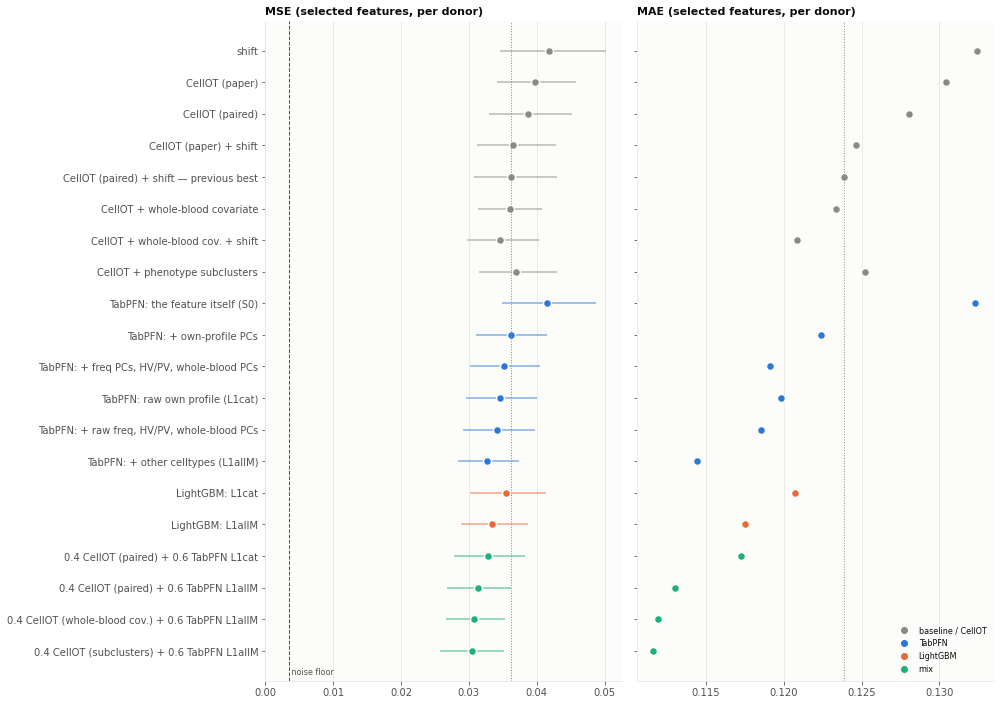

,MSE,MSE_lo,MSE_hi,MAE,share_shift_err_removed,share_reducible_removed,between_R2,better_than_CellOT_paper,better_than_CellOT_paired+shift,p_vs_CellOT_paired+shift
method,,,,,,,,,,
shift,0.0419,0.0346,0.0503,0.1324,0.0000,0.0000,0.5303,10.0,4.0,0.0024
CellOT_paper,0.0398,0.0341,0.0458,0.1304,0.0495,0.0541,0.5903,NaN,5.0,0.0955
CellOT_paired,0.0387,0.0329,0.0452,0.1280,0.0749,0.0819,0.5948,13.0,5.0,0.1447
CellOT_paper+shift,0.0365,0.0312,0.0428,0.1246,0.1277,0.1395,0.5995,14.0,7.0,0.2253
CellOT_paired+shift,0.0363,0.0308,0.0429,0.1239,0.1338,0.1462,0.6005,14.0,NaN,NaN
CellOT_pcblood,0.0360,0.0314,0.0408,0.1234,0.1389,0.1518,0.6178,16.0,8.0,0.8288
CellOT_pcblood+shift,0.0346,0.0297,0.0403,0.1208,0.1726,0.1886,0.6169,15.0,16.0,0.0028
CellOT_cluster,0.0370,0.0316,0.0430,0.1252,0.1168,0.1276,0.6155,18.0,10.0,0.6508
pfn_S0,0.0415,0.0348,0.0488,0.1323,0.0092,0.0100,0.5377,10.0,4.0,0.0033


**Reading.**
- Start, the paper's CellOT: MSE 0.0398, MAE 0.1304. The plain shift scores 0.0419.
- Previous best, paired CellOT + shift: MSE 0.0363, MAE 0.1239.
- **Now: 0.4 CellOT_cluster + 0.6 pfn_L1allM**, MSE 0.0305 (95 % CI 0.0257-0.0352), MAE 0.1116.
  - Against the paper's CellOT: **23 % lower MSE** and 14 % lower MAE.
  - Against the previous best: 16 % lower MSE, better for 18 of 19 donors (Wilcoxon p = 2e-05).
- Noise floor: 0.0036.

In [2]:
path = [("shift", "shift"), ("CellOT_paper", "CellOT (paper)"), ("CellOT_paired", "CellOT (paired)"),
        ("CellOT_paper+shift", "CellOT (paper) + shift"), (OLD, "CellOT (paired) + shift — previous best"),
        ("CellOT_pcblood", "CellOT + whole-blood covariate"), ("CellOT_pcblood+shift", "CellOT + whole-blood cov. + shift"),
        ("CellOT_cluster", "CellOT + phenotype subclusters"),
        ("pfn_S0", "TabPFN: the feature itself (S0)"), ("pfn_S1_5", "TabPFN: + own-profile PCs"),
        ("pfn_S4_3", "TabPFN: + freq PCs, HV/PV, whole-blood PCs"), ("pfn_L1cat", "TabPFN: raw own profile (L1cat)"),
        ("pfn_L1all_raw", "TabPFN: + raw freq, HV/PV, whole-blood PCs"), ("pfn_L1allM", "TabPFN: + other celltypes (L1allM)"),
        ("lgb_L1cat", "LightGBM: L1cat"), ("lgb_L1allM", "LightGBM: L1allM"),
        ("0.4 CellOT_paired + 0.6 pfn_L1cat", "0.4 CellOT (paired) + 0.6 TabPFN L1cat"),
        ("0.4 CellOT_paired + 0.6 pfn_L1allM", "0.4 CellOT (paired) + 0.6 TabPFN L1allM"),
        ("0.4 CellOT_pcblood + 0.6 pfn_L1allM", "0.4 CellOT (whole-blood cov.) + 0.6 TabPFN L1allM"),
        ("0.4 CellOT_cluster + 0.6 pfn_L1allM", "0.4 CellOT (subclusters) + 0.6 TabPFN L1allM")]
path = [(m, l) for m, l in path if has(m)]
if best not in [m for m, _ in path]: path.append((best, f"best overall: {best}"))
fig, axs = plt.subplots(1, 2, figsize=(14, 0.42 * len(path) + 1.5), sharey=True)
y = np.arange(len(path))[::-1]
for ax, met in zip(axs, ["MSE", "MAE"]):
    for yi, (m, lab) in zip(y, path):
        c = COL[fam(m)]
        if met == "MSE": ax.hlines(yi, M.loc[m, "MSE_lo"], M.loc[m, "MSE_hi"], color=c, lw=1.5, alpha=0.6)
        ax.plot(M.loc[m, met], yi, "o", color=c, ms=8, mec="#fcfcfb", mew=1.5)
    if met == "MSE":
        ax.axvline(FLOOR, color=INK2, ls="--", lw=1); ax.text(FLOOR, -0.8, " noise floor", color=INK2, fontsize=8, va="bottom")
    ax.axvline(M.loc[OLD, met], color=REF, ls=":", lw=1)
    ax.set_title(f"{met} (selected features, per donor)", loc="left"); ax.grid(axis="y", visible=False)
axs[0].set_yticks(y); axs[0].set_yticklabels([l for _, l in path]); axs[0].set_xlim(left=0)
for f, c in COL.items(): axs[1].plot([], [], "o", color=c, label=f)
axs[1].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()
cols = ["MSE", "MSE_lo", "MSE_hi", "MAE", "share_shift_err_removed", "share_reducible_removed", "between_R2",
        "better_than_CellOT_paper", "better_than_CellOT_paired+shift", "p_vs_CellOT_paired+shift"]
display(M.loc[[m for m, _ in path], cols].round(4))
o, b = M.loc[OLD], M.loc[best]; p = M.loc["CellOT_paper"]
display(Markdown(f'''**Reading.**
- Start, the paper's CellOT: MSE {p.MSE:.4f}, MAE {p.MAE:.4f}. The plain shift scores {M.loc["shift","MSE"]:.4f}.
- Previous best, paired CellOT + shift: MSE {o.MSE:.4f}, MAE {o.MAE:.4f}.
- **Now: {best}**, MSE {b.MSE:.4f} (95 % CI {b.MSE_lo:.4f}-{b.MSE_hi:.4f}), MAE {b.MAE:.4f}.
  - Against the paper's CellOT: **{100*(1-b.MSE/p.MSE):.0f} % lower MSE** and {100*(1-b.MAE/p.MAE):.0f} % lower MAE.
  - Against the previous best: {100*(1-b.MSE/o.MSE):.0f} % lower MSE, better for {int(b['better_than_CellOT_paired+shift'])} of 19 donors (Wilcoxon p = {b['p_vs_CellOT_paired+shift']:.1g}).
- Noise floor: {FLOOR:.4f}.'''))

## 2. All methods, all metrics

Selected features first, then every case with a visible effect.

In [3]:
show = ["MSE", "MSE_lo", "MSE_hi", "MAE", "share_shift_err_removed", "share_reducible_removed", "between_R2",
        "better_than_CellOT_paper", "p_vs_CellOT_paper", "better_than_CellOT_paired+shift", "p_vs_CellOT_paired+shift"]
display(M.sort_values("MSE")[show].round(4))
display(Mf.sort_values("MSE")[["MSE", "MAE", "share_shift_err_removed", "share_reducible_removed", "between_R2"]].round(4))

,MSE,MSE_lo,MSE_hi,MAE,share_shift_err_removed,share_reducible_removed,between_R2,better_than_CellOT_paper,p_vs_CellOT_paper,better_than_CellOT_paired+shift,p_vs_CellOT_paired+shift
method,,,,,,,,,,,
0.4 CellOT_cluster + 0.6 pfn_L1allM,0.0304,0.0257,0.0352,0.1116,0.2726,0.2978,0.6641,19.0,0.0000,18.0,0.0000
0.4 CellOT_pcblood + 0.6 pfn_L1allM,0.0308,0.0266,0.0353,0.1119,0.2656,0.2902,0.6601,19.0,0.0000,16.0,0.0002
0.4 CellOT_film + 0.6 pfn_L1allM,0.0308,0.0264,0.0352,0.1119,0.2647,0.2893,0.6599,19.0,0.0000,16.0,0.0005
0.4 CellOT_cluster + 0.6 lgb_L1allM,0.0310,0.0264,0.0362,0.1133,0.2601,0.2842,0.6576,19.0,0.0000,18.0,0.0000
0.4 CellOT_pcblood + 0.6 lgb_L1allM,0.0312,0.0270,0.0360,0.1136,0.2545,0.2781,0.6540,19.0,0.0000,17.0,0.0010
0.4 CellOT_film + 0.6 lgb_L1allM,0.0312,0.0271,0.0359,0.1136,0.2539,0.2774,0.6539,19.0,0.0000,17.0,0.0010
0.4 CellOT_paired + 0.6 pfn_L1allM,0.0313,0.0267,0.0362,0.1130,0.2529,0.2764,0.6546,19.0,0.0000,16.0,0.0004
0.4 CellOT_cluster + 0.6 lgb_L1F,0.0314,0.0272,0.0354,0.1151,0.2506,0.2738,0.6533,19.0,0.0000,17.0,0.0002
0.4 CellOT_paper + 0.6 pfn_L1allM,0.0314,0.0271,0.0364,0.1137,0.2488,0.2719,0.6536,19.0,0.0000,14.0,0.0010


,MSE,MAE,share_shift_err_removed,share_reducible_removed,between_R2
method,,,,,
0.4 CellOT_cluster + 0.6 pfn_L1allM,0.0188,0.0811,0.2634,0.2966,0.8215
0.4 CellOT_pcblood + 0.6 pfn_L1allM,0.0190,0.0813,0.2563,0.2886,0.8193
0.4 CellOT_film + 0.6 pfn_L1allM,0.0190,0.0813,0.2554,0.2876,0.8191
0.4 CellOT_cluster + 0.6 lgb_L1allM,0.0192,0.0826,0.2491,0.2804,0.8179
0.4 CellOT_paired + 0.6 pfn_L1allM,0.0193,0.0819,0.2451,0.2760,0.8167
0.4 CellOT_pcblood + 0.6 lgb_L1allM,0.0193,0.0828,0.2434,0.2741,0.8159
0.4 CellOT_film + 0.6 lgb_L1allM,0.0193,0.0828,0.2427,0.2732,0.8158
0.4 CellOT_cluster + 0.6 lgb_L1F,0.0194,0.0836,0.2396,0.2697,0.8157
0.4 CellOT_paper + 0.6 pfn_L1allM,0.0194,0.0826,0.2389,0.2690,0.8158


## 3. Patient specificity: how much of the donor-specific response is predicted

- **Share of the reducible error removed** counts what the shift misses that is not measurement noise. 0 = the shift,
  1 = everything real predicted.
- **between_R2** asks whether the predicted differences between donors follow the real ones. The shift already reaches
  a high value, because a donor's Unstim differences carry over to the stimulated state. The ceiling is set by noise.

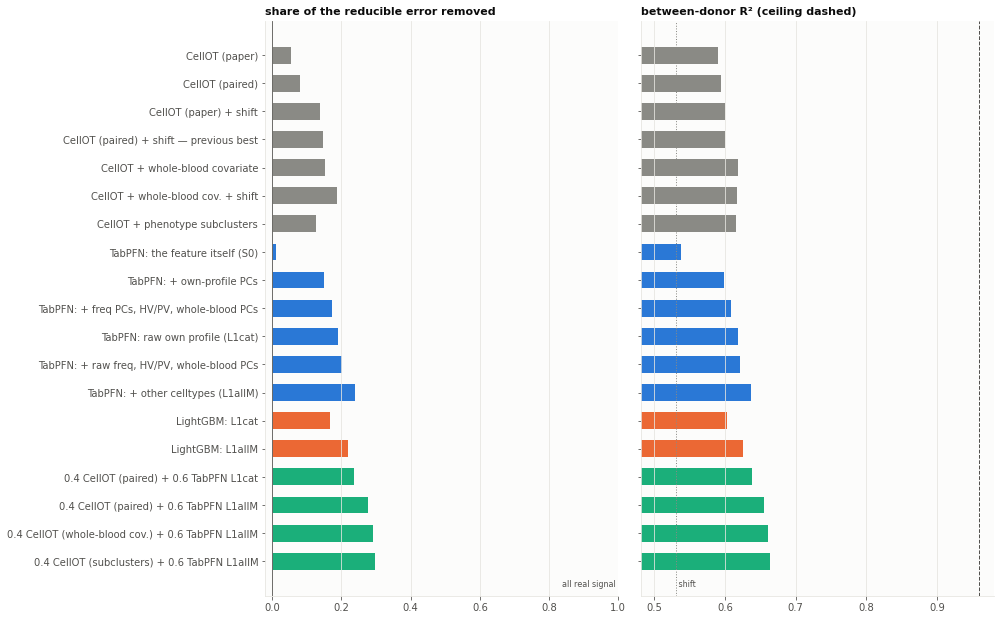

**Reading.**
- The best model predicts **30 %** of the real (non-noise) error the shift leaves. The paper's CellOT predicts 5 % and the previous best 15 %.
- Between-donor R²:
  - shift 0.530, previous best 0.600, now 0.664, against a noise ceiling of 0.960.
  - Of the donor-to-donor variation the shift cannot explain (0.470), the best model explains 28 %; the noise accounts for 8 %.

In [4]:
sel = [m for m, _ in path if m != "shift"]
lab = dict(path)
fig, axs = plt.subplots(1, 2, figsize=(14, 0.38 * len(sel) + 1.5), sharey=True)
y = np.arange(len(sel))[::-1]
for ax, met, ttl in [(axs[0], "share_reducible_removed", "share of the reducible error removed"),
                     (axs[1], "between_R2", "between-donor R² (ceiling dashed)")]:
    ax.barh(y, M.loc[sel, met], color=[COL[fam(m)] for m in sel], height=0.6)
    ax.set_title(ttl, loc="left"); ax.grid(axis="y", visible=False)
    if met == "between_R2":
        ax.axvline(CEIL, color=INK2, ls="--", lw=1); ax.axvline(M.loc["shift", met], color=REF, ls=":", lw=1)
        ax.set_xlim(M.loc[sel + ["shift"], met].min() - 0.05, CEIL + 0.02)
        ax.text(M.loc["shift", met], -0.9, " shift", color=INK2, fontsize=8)
    else:
        ax.axvline(0, color=INK2, lw=0.8); ax.set_xlim(min(0, M.loc[sel, met].min()) - 0.02, 1)
        ax.axvline(1, color=INK2, ls="--", lw=1); ax.text(1, -0.9, "all real signal ", color=INK2, fontsize=8, ha="right")
axs[0].set_yticks(y); axs[0].set_yticklabels([lab[m] for m in sel]); plt.tight_layout(); plt.show()
sh = M.loc["shift", "between_R2"]
display(Markdown(f'''**Reading.**
- The best model predicts **{100*b.share_reducible_removed:.0f} %** of the real (non-noise) error the shift leaves. The paper's CellOT predicts {100*p.share_reducible_removed:.0f} % and the previous best {100*o.share_reducible_removed:.0f} %.
- Between-donor R²:
  - shift {sh:.3f}, previous best {o.between_R2:.3f}, now {b.between_R2:.3f}, against a noise ceiling of {CEIL:.3f}.
  - Of the donor-to-donor variation the shift cannot explain ({1-sh:.3f}), the best model explains {(b.between_R2-sh)/(1-sh)*100:.0f} %; the noise accounts for {(1-CEIL)/(1-sh)*100:.0f} %.'''))

## 4. Noise: how far we got, and what is left

Each bar is the shift's MSE split into three parts:
- **removed**: the improvement over the shift;
- **left to gain**: the error above the noise floor;
- **noise**: what no model can remove.

The per-stim version follows, then the between-donor variance split into: explained by the shift, extra explained by
the model, real but unexplained, and noise.

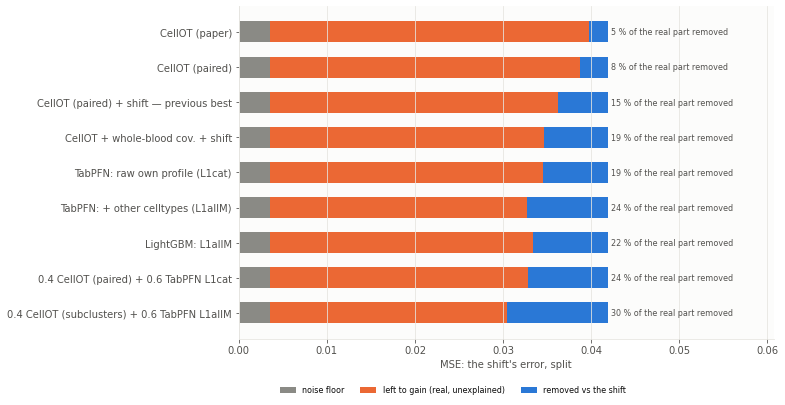

In [5]:
ms = [m for m in ["CellOT_paper", "CellOT_paired", OLD, "CellOT_pcblood+shift", "pfn_L1cat", "pfn_L1allM", "lgb_L1allM",
                  "0.4 CellOT_paired + 0.6 pfn_L1cat", best] if has(m)]
ms = list(dict.fromkeys(ms)); sh_mse = M.loc["shift", "MSE"]
fig, ax = plt.subplots(figsize=(11, 0.5 * len(ms) + 1.2)); y = np.arange(len(ms))[::-1]
rem = np.array([sh_mse - M.loc[m, "MSE"] for m in ms]); left = np.array([M.loc[m, "MSE"] - FLOOR for m in ms])
ax.barh(y, [FLOOR] * len(ms), color=REF, height=0.6, label="noise floor")
ax.barh(y, left, left=FLOOR, color=S2, height=0.6, label="left to gain (real, unexplained)")
ax.barh(y, rem, left=FLOOR + left, color=S1, height=0.6, label="removed vs the shift")
for yi, m in zip(y, ms):
    ax.text(sh_mse * 1.01, yi, f"{100 * M.loc[m, 'share_reducible_removed']:.0f} % of the real part removed", va="center", fontsize=8, color=INK2)
ax.set_yticks(y); ax.set_yticklabels([lab.get(m, m) for m in ms]); ax.set_xlim(0, sh_mse * 1.45)
ax.set_xlabel("MSE: the shift's error, split"); ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.12), ncol=3, fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

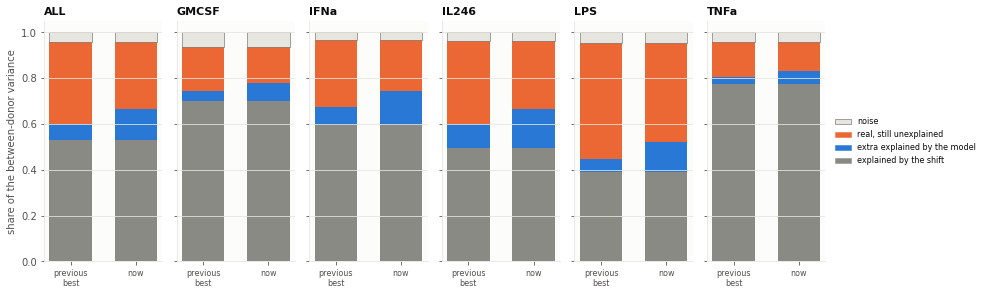

method,0.4 CellOT_cluster + 0.6 pfn_L1allM,CellOT_paired+shift,shift,noise,real unexplained (now)
stim,,,,,
ALL,0.664,0.600,0.530,0.040,0.296
GMCSF,0.781,0.746,0.700,0.063,0.155
IFNa,0.742,0.673,0.596,0.031,0.227
IL246,0.666,0.600,0.495,0.036,0.298
LPS,0.522,0.446,0.389,0.044,0.433
TNFa,0.830,0.804,0.776,0.042,0.127


In [6]:
V = VR[VR.method.isin(["shift", OLD, best])]
stims = ["ALL"] + sorted(set(VR.stim) - {"ALL"})
fig, axs = plt.subplots(1, len(stims), figsize=(2.3 * len(stims), 4.2), sharey=True)
for ax, st in zip(axs, stims):
    v = V[V.stim == st].set_index("method"); base = v.loc["shift", "baseline_shift"]; nz = v.loc["shift", "noise"]
    for i, (m, nm) in enumerate([(OLD, "previous\nbest"), (best, "now")]):
        ex = v.loc[m, "explained"] - base; unex = 1 - v.loc[m, "explained"] - nz
        ax.bar(i, base, color=REF, width=0.65); ax.bar(i, ex, bottom=base, color=S1, width=0.65)
        ax.bar(i, unex, bottom=base + ex, color=S2, width=0.65); ax.bar(i, nz, bottom=base + ex + unex, color=GRID, width=0.65, edgecolor=INK2, lw=0.5)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["previous\nbest", "now"], fontsize=8); ax.set_title(st, loc="left"); ax.grid(axis="x", visible=False)
axs[0].set_ylabel("share of the between-donor variance")
from matplotlib.patches import Patch
hs = [Patch(facecolor=c, edgecolor=INK2 if c == GRID else c, lw=0.5, label=l) for c, l in
      [(GRID, "noise"), (S2, "real, still unexplained"), (S1, "extra explained by the model"), (REF, "explained by the shift")]]
axs[-1].legend(handles=hs, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8); plt.tight_layout(); plt.show()
t = V.pivot_table(index="stim", columns="method", values="explained").reindex(stims)
t["noise"] = V[V.method == "shift"].set_index("stim").noise.reindex(stims)
t["real unexplained (now)"] = 1 - t[best] - t["noise"]; display(t.round(3))

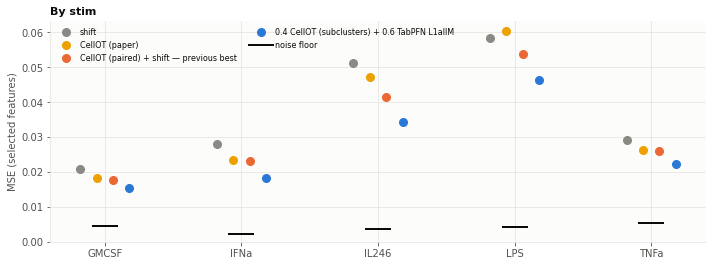

In [7]:
fl = pd.read_pickle(FIN / "cases.pkl"); fl = fl[fl.set.str.startswith("rule")]
F = pd.read_pickle(FIN / "noise_floor.pkl")
fl = fl.merge(F, on=["stim", "celltype", "donor", "q", "marker"], how="left")
floor_stim = fl.groupby("stim").floor_resp.mean()
cmp_ms = [m for m in ["shift", "CellOT_paper", OLD, best] if has(m)]
fig, ax = plt.subplots(figsize=(10, 3.8)); st = BS.columns.tolist(); x = np.arange(len(st))
for i, (m, c) in enumerate(zip(cmp_ms, [REF, S4, S2, S1])):
    ax.plot(x + (i - 1.5) * 0.12, BS.loc[m, st], "o", color=c, ms=8, label=lab.get(m, m))
ax.plot(x, floor_stim.reindex(st), "_", color=INK, ms=26, mew=2, label="noise floor")
ax.set_xticks(x); ax.set_xticklabels(st); ax.set_ylabel("MSE (selected features)"); ax.set_ylim(0)
ax.legend(fontsize=8, ncol=2); ax.set_title("By stim", loc="left"); plt.tight_layout(); plt.show()

## 5. Which CellOT to mix with which tabular model

MSE of `0.4 · CellOT + 0.6 · model` for every pair. The first column is `CellOT + shift` (0.5 / 0.5), for reference.

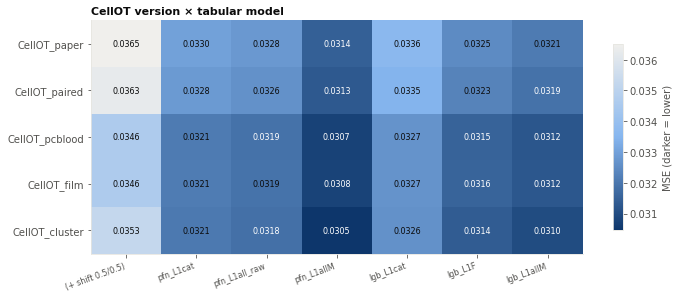

In [8]:
cels = [c for c in ["CellOT_paper", "CellOT_paired", "CellOT_pcblood", "CellOT_film", "CellOT_cluster"] if has(c)]
mods = [m for m in ["pfn_L1cat", "pfn_L1all_raw", "pfn_L1allM", "lgb_L1cat", "lgb_L1F", "lgb_L1allM"] if has(m)]
H = pd.DataFrame({m: [M.loc[f"0.4 {c} + 0.6 {m}", "MSE"] if has(f"0.4 {c} + 0.6 {m}") else np.nan for c in cels] for m in mods}, index=cels)
H.insert(0, "(+ shift 0.5/0.5)", [M.loc[f"{c}+shift", "MSE"] for c in cels])
fig, ax = plt.subplots(figsize=(10, 0.55 * len(cels) + 1.5))
im = ax.imshow(H.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", ["#0d366b", "#86b6ef", "#f0efec"]), aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v:.4f}", ha="center", va="center", fontsize=8, color="#ffffff" if v < np.nanpercentile(H.values, 40) else INK)
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels(H.columns, rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels(cels); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="MSE (darker = lower)"); ax.set_title("CellOT version × tabular model", loc="left"); plt.tight_layout(); plt.show()

## 6. Donor by donor

Each line is one left-out donor: MSE with the previous best (paired CellOT + shift) and with the best model now.

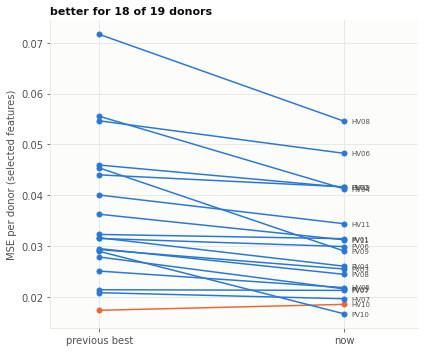

In [9]:
d = BD[[OLD, best]].sort_values(OLD)
fig, ax = plt.subplots(figsize=(6, 5))
for dn, r in d.iterrows():
    c = S1 if r[best] < r[OLD] else S2
    ax.plot([0, 1], [r[OLD], r[best]], "-o", color=c, lw=1.5, ms=5); ax.text(1.03, r[best], dn, fontsize=7, va="center", color=INK2)
ax.set_xticks([0, 1]); ax.set_xticklabels(["previous best", "now"]); ax.set_ylabel("MSE per donor (selected features)")
ax.set_xlim(-0.2, 1.3); ax.set_title(f"better for {int((d[best] < d[OLD]).sum())} of {len(d)} donors", loc="left"); plt.tight_layout(); plt.show()

## 7. Which feature blocks matter: removing one block at a time from TabPFN L1allM

L1allM = base (7) + own profile (65) + 28 raw log frequencies + HV/PV + 3 whole-blood PCs + `mk28` (the row's quantile ×
marker in all 28 celltypes) + `dw` (their mean and spread). The base, `mk28` and `dw` are always kept. Same LODO frame and
selected features; "better" = donors (of 19) where the variant beats L1allM. Mix = 0.4 subcluster CellOT + 0.6 TabPFN.
Results: `work/lc/tab/abl_lodo/lin_summary.csv`.

In [10]:
A = pd.read_csv(WORK / "tab" / "abl_lodo" / "lin_summary.csv").set_index("method")
abl = [("pfn_L1allM", "L1allM (134 columns)"), ("pfn_L1allM_noBPC", "without whole-blood PCs (131)"),
       ("pfn_L1allM_noFreq", "without frequencies (106)"), ("pfn_L1allM_noOwn", "without own profile (69)"),
       ("pfn_Mmin", "base + mk28 + dw only (37)"), ("pfn_L1M", "reference: L1M (102)"), ("pfn_L1cat", "reference: L1cat (72)")]
T7 = pd.DataFrame([{"variant": l, "MSE": A.loc[m, "MSE_donor"], "MAE": A.loc[m, "MAE_donor"], "better than L1allM": A.loc[m, "donors_better"],
                    "p": A.loc[m, "p"], "mix MSE": A.loc["mix_" + m, "MSE_donor"], "mix MAE": A.loc["mix_" + m, "MAE_donor"]} for m, l in abl]).set_index("variant")
display(T7.round(4))
D7 = pd.read_pickle(WORK / "tab" / "abl_lodo" / "cases.pkl"); D7 = D7[D7.set.str.startswith("rule")]
display(pd.DataFrame({st: {l: ((g[m] - g.true) ** 2).mean() for m, l in abl[:5]} for st, g in D7.groupby("stim")}).round(4))

,MSE,MAE,better than L1allM,p,mix MSE,mix MAE
variant,,,,,,
L1allM (134 columns),0.0327,0.1145,NaN,NaN,0.0304,0.1116
without whole-blood PCs (131),0.0325,0.1143,10.0,0.6226,0.0304,0.1114
without frequencies (106),0.0332,0.1162,9.0,0.5153,0.0308,0.1126
without own profile (69),0.0343,0.1163,6.0,0.1447,0.0306,0.1117
base + mk28 + dw only (37),0.0383,0.1259,4.0,0.0006,0.0340,0.1187
reference: L1M (102),0.0340,0.1172,6.0,0.0361,0.0312,0.1134
reference: L1cat (72),0.0346,0.1198,5.0,0.0289,0.0321,0.1158


,GMCSF,IFNa,IL246,LPS,TNFa
L1allM (134 columns),0.0164,0.0190,0.0396,0.0486,0.0233
without whole-blood PCs (131),0.0161,0.0192,0.0393,0.0482,0.0235
without frequencies (106),0.0166,0.0202,0.0379,0.0504,0.0230
without own profile (69),0.0164,0.0193,0.0484,0.0468,0.0238
base + mk28 + dw only (37),0.0170,0.0240,0.0479,0.0555,0.0242


**Reading.**
- Whole-blood PCs add nothing; removing them is neutral or slightly better.
- The own profile is the most important block, mostly for IL246 (+22 % MSE without it). It is not needed for LPS.
- Frequencies add a little, mostly for IFNa and LPS.
- The row-aligned columns alone (base + mk28 + dw) are far from enough. The gain comes from combining them with the
  donor's own profile and composition.

## 8. Fewer columns at the same performance

Starting from L1allM without whole-blood PCs (131 columns), the own profile and the frequencies were replaced by smaller
representations. Base, `mk28`, `dw` and HV/PV are always kept.
- Own profile: q50-q90 only, medians, per-marker mean + q90 − q10 spread, 5 marker-pathway averages, 5 / 10 / 15 PCs, or
  3 / 5 / 10 PLS components. The PLS is supervised on the table's residual target and fitted without the donor's own
  target.
- Frequencies: 3 / 5 / 10 PCs, 3 / 5 PLS components, or 8 lineage frequencies.
- Plus compact combinations.

Results: `work/lc/tab/red_lodo/lin_summary.csv`.

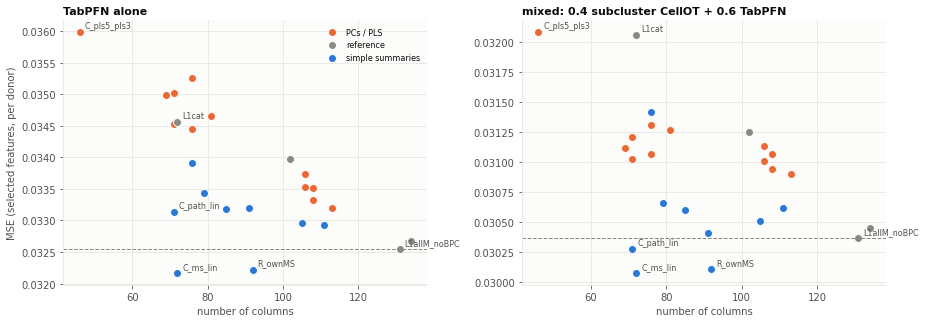

,columns,family,MSE,MAE,better than ref,p,mix MSE,mix MAE
variant,,,,,,,,
C_ms_lin,72,simple summaries,0.0322,0.1138,10.0,0.8288,0.0301,0.1110
R_ownMS,92,simple summaries,0.0322,0.1133,13.0,0.2753,0.0301,0.1107
L1allM_noBPC,131,reference,0.0325,0.1143,NaN,NaN,0.0304,0.1114
L1allM,134,reference,0.0327,0.1145,9.0,0.6226,0.0304,0.1116
R_frLin,111,simple summaries,0.0329,0.1155,8.0,0.2935,0.0306,0.1122
R_ownq3,105,simple summaries,0.0330,0.1145,9.0,0.3321,0.0305,0.1113
C_path_lin,71,simple summaries,0.0331,0.1151,8.0,0.3525,0.0303,0.1113
C_q3_lin,85,simple summaries,0.0332,0.1152,5.0,0.1336,0.0306,0.1118
R_frPC10,113,PCs / PLS,0.0332,0.1160,6.0,0.1564,0.0309,0.1127


**Reading.** The compact set **C_ms_lin (72 columns)** keeps the performance of 131 columns: MSE 0.0322 vs 0.0325 alone, 0.0301 vs 0.0304 mixed; MAE 0.1138 vs 0.1143. Its columns: base (7) + mk28 + dw + HV/PV + the own profile summarised per marker as mean and q90 − q10 spread (26) + 8 lineage frequencies.

Simple, readable summaries work; PCs and PLS lose 3-8 %. With 18 donors, compressions fitted on the donors discard or overfit what matters. Removing the frequencies entirely (L1M_q3) costs.

In [11]:
R8 = pd.read_csv(WORK / "tab" / "red_lodo" / "lin_summary.csv").set_index("method")
ncol = {"L1allM_noBPC": 131, "L1allM": 134, "L1M": 102, "L1cat": 72, "R_ownq3": 105, "R_ownq50": 79, "R_ownMS": 92, "R_ownPath": 91,
        "R_ownPC5": 71, "R_ownPC10": 76, "R_ownPC15": 81, "R_ownPLS3": 69, "R_ownPLS5": 71, "R_ownPLS10": 76, "R_frPC3": 106,
        "R_frPC5": 108, "R_frPC10": 113, "R_frPLS3": 106, "R_frPLS5": 108, "R_frLin": 111, "L1M_q3": 76, "C_q3_lin": 85,
        "C_ms_lin": 72, "C_path_lin": 71, "C_pls5_pls3": 46}
def grp(v):
    if v in ("L1allM_noBPC", "L1allM", "L1M", "L1cat"): return "reference"
    if "PC" in v or "PLS" in v or "pls" in v: return "PCs / PLS"
    return "simple summaries"
cmap = {"reference": REF, "simple summaries": S1, "PCs / PLS": S2}
T8 = pd.DataFrame([{"variant": v, "columns": n, "family": grp(v), "MSE": R8.loc["pfn_" + v, "MSE_donor"], "MAE": R8.loc["pfn_" + v, "MAE_donor"],
                    "better than ref": R8.loc["pfn_" + v, "donors_better"], "p": R8.loc["pfn_" + v, "p"],
                    "mix MSE": R8.loc["mix_pfn_" + v, "MSE_donor"], "mix MAE": R8.loc["mix_pfn_" + v, "MAE_donor"]} for v, n in ncol.items()]).set_index("variant")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True)
for ax, met in zip(axs, ["MSE", "mix MSE"]):
    for f, g in T8.groupby("family"): ax.plot(g["columns"], g[met], "o", color=cmap[f], ms=8, mec="#fcfcfb", mew=1, label=f)
    ax.axhline(T8.loc["L1allM_noBPC", met], color=REF, ls="--", lw=1)
    for v in ["C_ms_lin", "R_ownMS", "C_path_lin", "L1allM_noBPC", "C_pls5_pls3", "L1cat"]:
        ax.annotate(v, (T8.loc[v, "columns"], T8.loc[v, met]), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_xlabel("number of columns")
    ax.set_title("TabPFN alone" if met == "MSE" else "mixed: 0.4 subcluster CellOT + 0.6 TabPFN", loc="left")
axs[0].set_ylabel("MSE (selected features, per donor)"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(T8.sort_values("MSE").round(4))
b8 = T8.loc["C_ms_lin"]; r8 = T8.loc["L1allM_noBPC"]
txt = ("**Reading.** The compact set **C_ms_lin (72 columns)** keeps the performance of 131 columns: MSE "
       f"{b8.MSE:.4f} vs {r8.MSE:.4f} alone, {b8['mix MSE']:.4f} vs {r8['mix MSE']:.4f} mixed; MAE {b8.MAE:.4f} vs {r8.MAE:.4f}. "
       "Its columns: base (7) + mk28 + dw + HV/PV + the own profile summarised per marker as mean and q90 − q10 spread (26) "
       "+ 8 lineage frequencies.\n\n"
       "Simple, readable summaries work; PCs and PLS lose 3-8 %. With 18 donors, compressions fitted on the donors discard "
       "or overfit what matters. Removing the frequencies entirely (L1M_q3) costs.")
display(Markdown(txt))

## 9. TabPFN checkpoints and their average (compact set)

The default `tabpfn-v2-regressor` and the three other v2 regressor checkpoints from Prior Labs (`09gpqh39`, `2noar4o2`,
`wyl4o83o`; the last one is a smaller network), and the average of their predicted corrections. Results:
`work/lc/tab/ckpt_lodo/lin_summary.csv`.

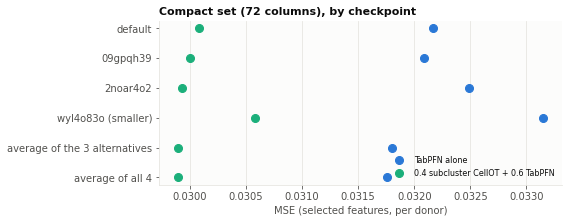

,MSE,MAE,better than default,p,mix MSE,mix MAE
checkpoint,,,,,,
default,0.0322,0.1138,NaN,NaN,0.0301,0.1110
09gpqh39,0.0321,0.1135,10.0,0.5949,0.0300,0.1108
2noar4o2,0.0325,0.1142,6.0,0.3321,0.0299,0.1108
wyl4o83o (smaller),0.0332,0.1154,9.0,0.4180,0.0306,0.1119
average of the 3 alternatives,0.0318,0.1131,11.0,0.2101,0.0299,0.1107
average of all 4,0.0318,0.1131,11.0,0.0546,0.0299,0.1107


**Reading.** The checkpoints are nearly interchangeable: their predicted corrections correlate about .98 with the default's.
- Averaging all 4 gives a small, borderline gain alone: MSE 0.0322 → 0.0318, better for 11/19 donors, p = 0.05.
- In the mix with CellOT the gain almost vanishes: 0.0301 → 0.0299.
- A single default checkpoint is the simpler choice (4× cheaper).

In [12]:
C9 = pd.read_csv(WORK / "tab" / "ckpt_lodo" / "lin_summary.csv").set_index("method")
ck = [("pfn_default", "default"), ("pfn_ck09", "09gpqh39"), ("pfn_ck2no", "2noar4o2"), ("pfn_ckwyl", "wyl4o83o (smaller)"),
      ("pfn_avg3", "average of the 3 alternatives"), ("pfn_avg4", "average of all 4")]
T9 = pd.DataFrame([{"checkpoint": l, "MSE": C9.loc[m, "MSE_donor"], "MAE": C9.loc[m, "MAE_donor"], "better than default": C9.loc[m, "donors_better"],
                    "p": C9.loc[m, "p"], "mix MSE": C9.loc["mix_" + m, "MSE_donor"], "mix MAE": C9.loc["mix_" + m, "MAE_donor"]} for m, l in ck]).set_index("checkpoint")
fig, ax = plt.subplots(figsize=(8, 3.2)); y = np.arange(len(T9))[::-1]
ax.plot(T9.MSE, y, "o", color=S1, ms=8, label="TabPFN alone"); ax.plot(T9["mix MSE"], y, "o", color=S3, ms=8, label="0.4 subcluster CellOT + 0.6 TabPFN")
ax.set_yticks(y); ax.set_yticklabels(T9.index); ax.grid(axis="y", visible=False); ax.set_xlabel("MSE (selected features, per donor)")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Compact set (72 columns), by checkpoint", loc="left"); plt.tight_layout(); plt.show()
display(T9.round(4))
d9, a9 = T9.loc["default"], T9.loc["average of all 4"]
display(Markdown("**Reading.** The checkpoints are nearly interchangeable: their predicted corrections correlate about .98 with the default's.\n"
                 f"- Averaging all 4 gives a small, borderline gain alone: MSE {d9.MSE:.4f} → {a9.MSE:.4f}, better for "
                 f"{int(a9['better than default'])}/19 donors, p = {a9.p:.2f}.\n"
                 f"- In the mix with CellOT the gain almost vanishes: {d9['mix MSE']:.4f} → {a9['mix MSE']:.4f}.\n"
                 "- A single default checkpoint is the simpler choice (4× cheaper)."))

## 10. Summary

In [13]:
rows = []
for m in [m for m in ["shift", "CellOT_paper", "CellOT_paired", OLD, "CellOT_pcblood+shift", "pfn_L1cat", "pfn_L1allM",
                      "lgb_L1allM", "0.4 CellOT_paired + 0.6 pfn_L1allM", best] if has(m)]:
    r = M.loc[m]; rows.append({"method": lab.get(m, m), "MSE": r.MSE, "MAE": r.MAE, "vs paper CellOT (MSE)": f"{100*(r.MSE/p.MSE-1):+.0f} %",
                               "share of reducible error removed": f"{100*r.share_reducible_removed:.0f} %", "between_R2": r.between_R2})
rows.append({"method": "noise floor (no model can go lower)", "MSE": FLOOR, "between_R2": CEIL})
display(pd.DataFrame(rows).drop_duplicates("method").set_index("method").round(4))
display(Markdown(f'''- From the paper's CellOT to **{best}**: MSE {p.MSE:.4f} → {b.MSE:.4f} ({100*(1-b.MSE/p.MSE):.0f} % lower), MAE {p.MAE:.4f} → {b.MAE:.4f}.
- From the previous best, paired CellOT + shift: {100*(1-b.MSE/o.MSE):.0f} % lower MSE, better for {int(b['better_than_CellOT_paired+shift'])} of 19 donors.
- Of what the shift misses and is not noise, **{100*b.share_reducible_removed:.0f} %** is now predicted; the paper's CellOT predicted {100*p.share_reducible_removed:.0f} %.
- What is left: **{100*(b.MSE-FLOOR)/b.MSE:.0f} %** of the remaining error is real, donor-specific signal not yet explained. **{100*FLOOR/b.MSE:.0f} %** is measurement noise.'
- The same performance with fewer columns: the compact 72-column set, mixed 0.4 with the subcluster CellOT, gives MSE {T8.loc['C_ms_lin','mix MSE']:.4f}, MAE {T8.loc['C_ms_lin','mix MAE']:.4f}; averaging 4 TabPFN checkpoints: {T9.loc['average of all 4','mix MSE']:.4f} / {T9.loc['average of all 4','mix MAE']:.4f}.'''))

,MSE,MAE,vs paper CellOT (MSE),share of reducible error removed,between_R2
method,,,,,
shift,0.0419,0.1324,+5 %,0 %,0.5303
CellOT (paper),0.0398,0.1304,+0 %,5 %,0.5903
CellOT (paired),0.0387,0.1280,-3 %,8 %,0.5948
CellOT (paired) + shift — previous best,0.0363,0.1239,-9 %,15 %,0.6005
CellOT + whole-blood cov. + shift,0.0346,0.1208,-13 %,19 %,0.6169
TabPFN: raw own profile (L1cat),0.0346,0.1198,-13 %,19 %,0.6180
TabPFN: + other celltypes (L1allM),0.0327,0.1145,-18 %,24 %,0.6368
LightGBM: L1allM,0.0334,0.1175,-16 %,22 %,0.6260
0.4 CellOT (paired) + 0.6 TabPFN L1allM,0.0313,0.1130,-21 %,28 %,0.6546


- From the paper's CellOT to **0.4 CellOT_cluster + 0.6 pfn_L1allM**: MSE 0.0398 → 0.0305 (23 % lower), MAE 0.1304 → 0.1116.
- From the previous best, paired CellOT + shift: 16 % lower MSE, better for 18 of 19 donors.
- Of what the shift misses and is not noise, **30 %** is now predicted; the paper's CellOT predicted 5 %.
- What is left: **88 %** of the remaining error is real, donor-specific signal not yet explained. **12 %** is measurement noise.'
- The same performance with fewer columns: the compact 72-column set, mixed 0.4 with the subcluster CellOT, gives MSE 0.0301, MAE 0.1110; averaging 4 TabPFN checkpoints: 0.0299 / 0.1107.